In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    'font.size': 14,        # Default text size
    'axes.titlesize': 18,   # Title size
    'axes.labelsize': 16,   # X and Y axis label size
    'xtick.labelsize': 14,  # X tick label size
    'ytick.labelsize': 14,  # Y tick label size
    'legend.fontsize': 14,  # Legend font size
    'figure.titlesize': 20  # Figure-level title size
})

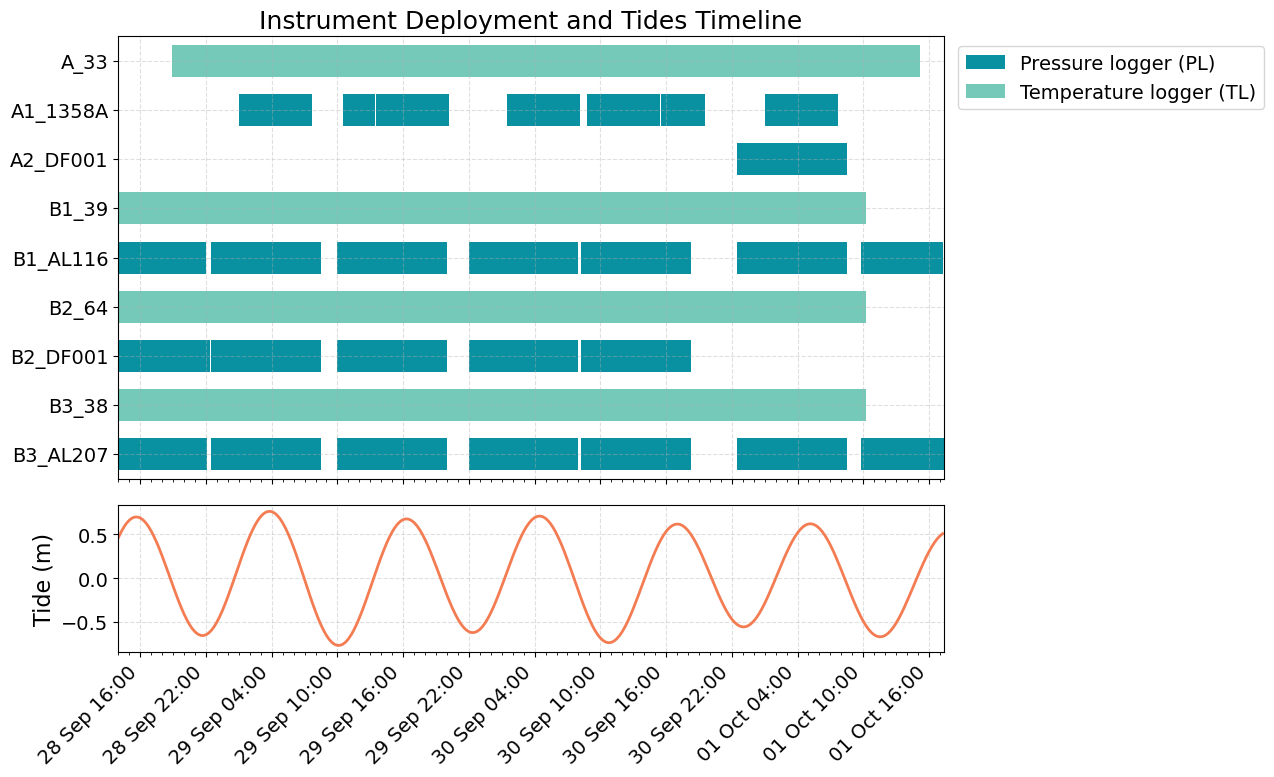

In [8]:
diver_folder = "../data/groundwater/DiverCSV"
temp_folder = "../data/groundwater/Temp"

# PL and TL data processing
def get_times(path, kind):
    if kind == "diver":
        d = pd.read_csv(path, encoding="latin-1", skiprows=51, usecols=[0])
        t = pd.to_datetime(d.iloc[:, 0].str.strip(), format="%Y/%m/%d %H:%M:%S.%f", errors="coerce")
    else:
        d = pd.read_csv(path, encoding="latin-1", sep=None, engine="python", skiprows=24, usecols=[0, 1])
        t = pd.to_datetime(d.iloc[:, 0].astype(str) + " " + d.iloc[:, 1].astype(str), errors="coerce")
    return t.min(), t.max()

label_map = {"23000000824F2141_092826200001_1": "B3_38",
             "9600000082456D41_092926005501_1": "A_33",
             "AE000000824F6A41_092826200001_1": "B2_64",
             "BA0000007FD53E41_092826200001_1": "B1_39"}

rows = []

for kind, folder in [("diver", diver_folder), ("temp", temp_folder)]:
    for filename in os.listdir(folder):
        path = os.path.join(folder, filename)

        if not os.path.isfile(path):
            continue

        name = filename.rsplit(".", 1)[0]
        if kind == "diver":
            parts = name.split("_")
            label = parts[0] + "_" + parts[2]
        else:
            label = label_map.get(name, name)
        start, end = get_times(folder + "/" + filename, kind)
        rows.append({"label": label, "kind": kind, "start": start, "end": end})

desired_order = ["A_33", "A1_1358A", "A2_DF001", "B1_39", "B1_AL116",
                 "B2_64", "B2_DF001", "B3_38", "B3_AL207"]

df = pd.DataFrame(rows).dropna()
df["y"] = df["label"].map({label: i for i, label in enumerate(desired_order)})
df = df.dropna(subset=["y"])
df["width"] = df["end"] - df["start"]

# tides data processing
tides = pd.read_csv("../data/water_levels/QUINTA_tides_2030.csv")
tides["dates"] = pd.to_datetime(tides["dates"], utc=True)
tides["dates"] = tides["dates"].dt.tz_convert("Etc/GMT+6").dt.tz_localize(None)
xmin = df["start"].min()
xmax = df["end"].max()
tides = tides[(tides["dates"] >= xmin) & (tides["dates"] <= xmax)]

fig, (ax, ax_tide) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

for kind, color, name in [("diver", "#0a91a1", "Pressure logger (PL)"),
                          ("temp", "#74c9b9", "Temperature logger (TL)")]:
    sub = df[df["kind"] == kind]
    ax.barh(sub["y"], sub["width"], left=sub["start"], height=0.65, color=color, label=name)

ax.set_title('Instrument Deployment and Tides Timeline')
ax.set_yticks(range(len(desired_order)))
ax.set_yticklabels(desired_order)
ax.set_ylim(len(desired_order) - 0.5, -0.5)
ax.grid(linestyle="--", alpha=0.4)
ax.legend(bbox_to_anchor=(1.4, 1.0), loc="upper right")

ax_tide.plot(tides["dates"], tides["tide"], color="#f47c53", linewidth=2)
ax_tide.set_ylabel("Tide (m)")
ax_tide.grid(linestyle="--", alpha=0.4)

ax_tide.set_xlim(xmin, xmax)
ax_tide.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax_tide.xaxis.set_minor_locator(mdates.HourLocator(interval=1))
ax_tide.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
plt.setp(ax_tide.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
